<a href="https://colab.research.google.com/github/KatiaItzelCortes/Simulaci-n-2/blob/main/Modelo_SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Modelo SIR con metropolis.

Se tiene como objetivo modelar el comportamiento de un brote epidémico utilizando el Modelo SIR que es un sistema de ecuaciones diferenciales, el cual divide a la población en tres compartimentos a lo largo del tiempo: Susceptibles ($S$), Infectados ($I$) y Removidos ($R$). Las dinámicas se rigen por el siguiente sistema de ecuaciones diferenciales:
$$\begin{align*} \frac{dS}{dt} &= -aSI \\ \frac{dI}{dt} &= aSI - bI \\ \frac{dR}{dt} &= bI \end{align*}$$
Graficamos los datos reales de un histórico brote de Influenza en un internado para observar la curva de infectados $I(t)$.

Los parámetros que gobiernan estas tasas de cambio son:

$β$ (Tasa de transmisión o contacto): Representa la probabilidad de que el contacto entre un individuo susceptible y uno infectado resulte en una nueva infección.

$α$ (Tasa de recuperación): Representa la proporción de individuos infectados que se recuperan por unidad de tiempo. Su inverso,
, equivale al tiempo promedio que una persona es contagiosa.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [27]:
t_dato = np.arange(15)
I_dato = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

S0, I0, R0 = 762, 1, 0
y0 = [S0, I0, R0]

1. Graficar datos

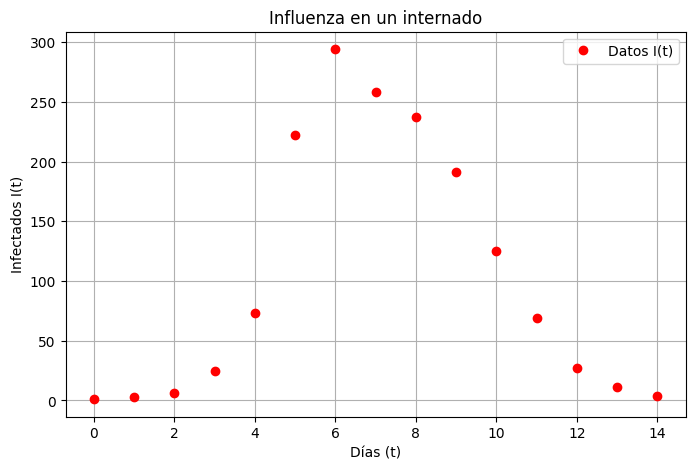

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(t_dato, I_dato, 'ro', label='Datos I(t)')
plt.title('Influenza en un internado')
plt.xlabel('Días (t)')
plt.ylabel('Infectados I(t)')
plt.legend()
plt.grid(True)
plt.show()

1. Graficar datos

In [29]:
def sir_modelo(y, t, a, b):
    S, I, R = y
    dS_dt = -a * S * I
    dI_dt = a * S * I - b * I
    dR_dt = b * I
    return [dS_dt, dI_dt, dR_dt]

In [30]:
def sol_sir(a, b, t):
    sol = odeint(sir_modelo, y0, t, args=(a, b))
    return sol[:, 1]

3. Plantear un ajuste por mínimos cuadrados

In [31]:
def chi_squared(a, b):
    I_modelo = sol_sir(a, b, t_dato)
    # Suma de los residuos
    return np.sum((I_dato - I_modelo)**2)

4. Usar el método MCMC (Metropolis-Hastings) para optimizar

In [32]:
def metropolis_h(iters=5000):
    con_a, con_b = 0.002, 0.4
    con_chi2 = chi_squared(con_a, con_b)

    muestras = []

    for i in range(iters):
        # Caminata aleatoria
        prop_a = np.random.normal(con_a, 0.0001)
        prop_b = np.random.normal(con_b, 0.01)

        if prop_a > 0 and prop_b > 0:
            prop_chi2 = chi_squared(prop_a, prop_b)


            log_alpha = -0.5 * (prop_chi2 - con_chi2)

            if np.log(np.random.rand()) < log_alpha:
                con_a, con_b = prop_a, prop_b
                con_chi2 = prop_chi2

        muestras.append((con_a, con_b))

    return np.array(muestras)

print("Parametros:")
mh_muestras = metropolis_h(iters=5000)
mej_a, mej_b = mh_muestras[-1]

print(f"a: {mej_a:.6f}")
print(f"b: {mej_b:.6f}")


Parametros:
a: 0.002181
b: 0.445084


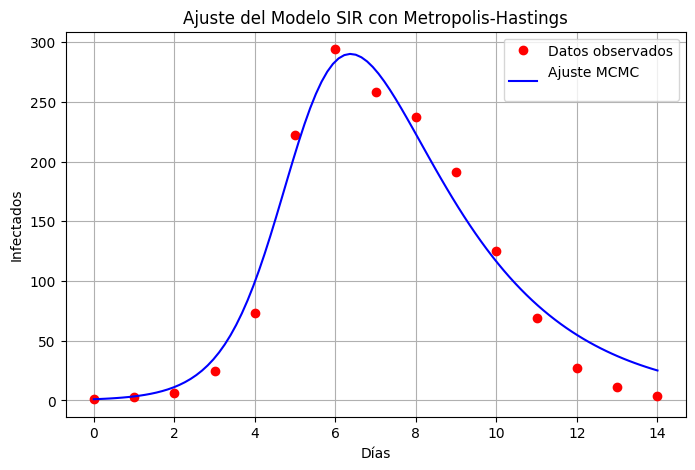

In [33]:

# Graficar el ajuste final sobre los datos
t_in = np.linspace(0, 14, 100)
I_f = sol_sir(mej_a, mej_b, t_in)

plt.figure(figsize=(8, 5))
plt.plot(t_dato, I_dato, 'ro', label='Datos observados')
plt.plot(t_in, I_f, 'b-', label=f'Ajuste MCMC\n')
plt.title('Ajuste del Modelo SIR con Metropolis-Hastings')
plt.xlabel('Días')
plt.ylabel('Infectados')
plt.legend()
plt.grid(True)
plt.show()